# From word vectors to stance predictions

We classify tweets as `none`, `against`, or `favor` towards atheism. Building on Project 1, we replace sparse features with GloVe and compare mean pooling with LSTM. The experiments show that class weighting and pretrained vectors help more consistently than a more complex encoder.

In [1]:
from pathlib import Path
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

cwd = Path.cwd()
PROJECT = next((p for p in [cwd, cwd / 'part2' / 'project_code', cwd / 'project_code']
                if (p / 'config.py').exists() and (p / 'results').is_dir()), None)
if PROJECT is None:
    raise FileNotFoundError('Open the notebook from the repository root or project_code')
RESULTS = PROJECT / 'results'
LOSS = RESULTS / 'loss_comparison_seeds035'
EMBED = RESULTS / 'embedding_comparison_seeds035'
ORDINARY0 = RESULTS / 'core_20261120_151445'
WEIGHTED0 = RESULTS / 'weighted_20261120_180229'
WEIGHTED35 = RESULTS / 'weighted_20261120_200129'

def table(frame, digits=3):
    display(frame.style.format(precision=digits))

def figure(path, caption):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(path)
    display(Image(filename=str(path)))
    display(Markdown('*' + caption + '*'))

loss_summary = pd.read_csv(LOSS / 'summary.csv')
loss_pairs = pd.read_csv(LOSS / 'paired_loss_differences.csv')
seed_means = pd.read_csv(LOSS / 'seed_means.csv')
embedding_summary = pd.read_csv(EMBED / 'summary.csv')

## Starting point

The training split contains 461 English tweets with uneven class frequencies. We start with GloVe WikiGiga 2024 (50d). Both encoders use the same lowercase word tokenizer, retaining punctuation and stopwords. Word IDs match GloVe's vocabulary; unknown words share UNK and padding is zero.

,label,n,proportion
0,none,105,0.228
1,against,273,0.592
2,favor,83,0.180


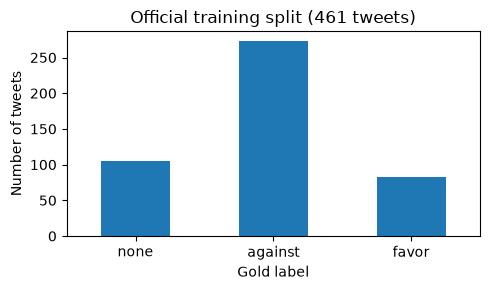

,version,n_tokens,n_oov,token_coverage
0,original,10905,786,0.928
1,without_semst,10444,325,0.969


,token,count
0,semst,461
1,lovewins,17
2,teamjesus,9
3,-ps,5
4,..,5
5,-prov,3
6,bha2015,3
7,scotusmarriage,3
8,tcot,3
9,whoisburningblackchurches,3


In [2]:
features = pd.read_csv(ORDINARY0 / 'analysis' / 'text_features.csv', keep_default_na=False)
label_names = ['none', 'against', 'favor']
counts = features['gold'].value_counts().reindex(range(3), fill_value=0)
class_counts = pd.DataFrame({'label': label_names, 'n': counts.values})
class_counts['proportion'] = class_counts['n'] / class_counts['n'].sum()
table(class_counts)
ax = class_counts.plot.bar(x='label', y='n', legend=False, rot=0, figsize=(5, 3))
ax.set(xlabel='Gold label', ylabel='Number of tweets', title='Official training split (461 tweets)')
plt.tight_layout()
plt.show()
table(pd.read_csv(ORDINARY0 / 'analysis' / 'marker_comparison.csv'))
table(pd.read_csv(ORDINARY0 / 'analysis' / 'oov_words.csv').head(10))

GloVe covers **92.79%** of tokens. Excluding the fixed `semst` marker raises coverage to **96.89%**. This changes only the analysis, not model inputs. Tweet-specific hashtags and the difference between GloVe's source domain and social media remain limitations.

### Experimental setup

We use five stratified outer folds, an inner validation split, and seeds 0, 3, 5. The checkpoint with minimum inner-validation NLL is evaluated on the outer fold. Comparisons share partitions and training settings; the official test split remains reserved.

In [3]:
settings = pd.DataFrame([
    ('Dataset', 'TweetEval stance_atheism; official train split'),
    ('Outer evaluation', '5 stratified folds per seed'),
    ('Inner validation', '20% of each outer training partition'),
    ('Seeds', '0, 3, 5; changes both partitions and training initialization'),
    ('Embedding', 'GloVe WikiGiga 2024, 50d; same vocabulary for random control'),
    ('Classifier head', '50 -> 50 -> 3, Tanh, dropout 0.1'),
    ('LSTM', '1 layer, hidden size 64, word dropout 0'),
    ('Optimization', 'AdamW, lr 0.001, weight decay 0.0001, batch size 64'),
    ('Budget', '20 epochs per fold'),
    ('Checkpoint', 'Minimum unweighted inner-validation NLL'),
    ('Metrics', 'Macro-F1, accuracy, mean F1 over against/favor'),
], columns=['Setting', 'Value'])
display(settings)
table(seed_means[['condition', 'system', 'seed', 'macro_f1', 'accuracy', 'stance_f1']])
table(loss_pairs.groupby('system')['macro_f1_difference'].agg(
    mean_difference='mean', improved_folds=lambda x: int((x > 0).sum()), paired_folds='count'
).reset_index())

,Setting,Value
0,Dataset,TweetEval stance_atheism; official train split
1,Outer evaluation,5 stratified folds per seed
2,Inner validation,20% of each outer training partition
3,Seeds,"0, 3, 5; changes both partitions and training ..."
4,Embedding,"GloVe WikiGiga 2024, 50d; same vocabulary for ..."
5,Classifier head,"50 -> 50 -> 3, Tanh, dropout 0.1"
6,LSTM,"1 layer, hidden size 64, word dropout 0"
7,Optimization,"AdamW, lr 0.001, weight decay 0.0001, batch si..."
8,Budget,20 epochs per fold
9,Checkpoint,Minimum unweighted inner-validation NLL


,condition,system,seed,macro_f1,accuracy,stance_f1
0,ordinary,lstm_finetuned,0,0.405,0.640,0.391
1,ordinary,lstm_finetuned,3,0.408,0.629,0.392
2,ordinary,lstm_finetuned,5,0.475,0.640,0.433
3,ordinary,lstm_frozen,0,0.431,0.655,0.401
4,ordinary,lstm_frozen,3,0.386,0.623,0.380
5,ordinary,lstm_frozen,5,0.487,0.666,0.421
6,ordinary,pooling_finetuned,0,0.457,0.670,0.406
7,ordinary,pooling_finetuned,3,0.454,0.657,0.424
8,ordinary,pooling_finetuned,5,0.456,0.664,0.401
9,ordinary,pooling_frozen,0,0.343,0.614,0.376


,system,mean_difference,improved_folds,paired_folds
0,lstm_finetuned,0.152,14,15
1,lstm_frozen,0.151,13,15
2,pooling_finetuned,0.154,15,15
3,pooling_frozen,0.217,15,15


Each configuration has 15 fold scores. Their variation is descriptive: folds overlap and seeds reuse the same texts. Outer-fold findings guided later experiments, so these are exploratory comparisons, not an untouched final benchmark.

## Experiments and findings

### Pooling and class weighting

We compare frozen and fine-tuned mean pooling. Ordinary-loss models rarely predict `favor`, motivating inverse-frequency class weights computed only from the inner training subset. Validation and evaluation remain unweighted.

,condition,system,macro_f1_mean,macro_f1_std,accuracy_mean,stance_f1_mean
2,ordinary,pooling_finetuned,0.456,0.050,0.664,0.410
3,ordinary,pooling_frozen,0.348,0.062,0.615,0.376
6,weighted,pooling_finetuned,0.610,0.052,0.664,0.601
7,weighted,pooling_frozen,0.565,0.044,0.621,0.549


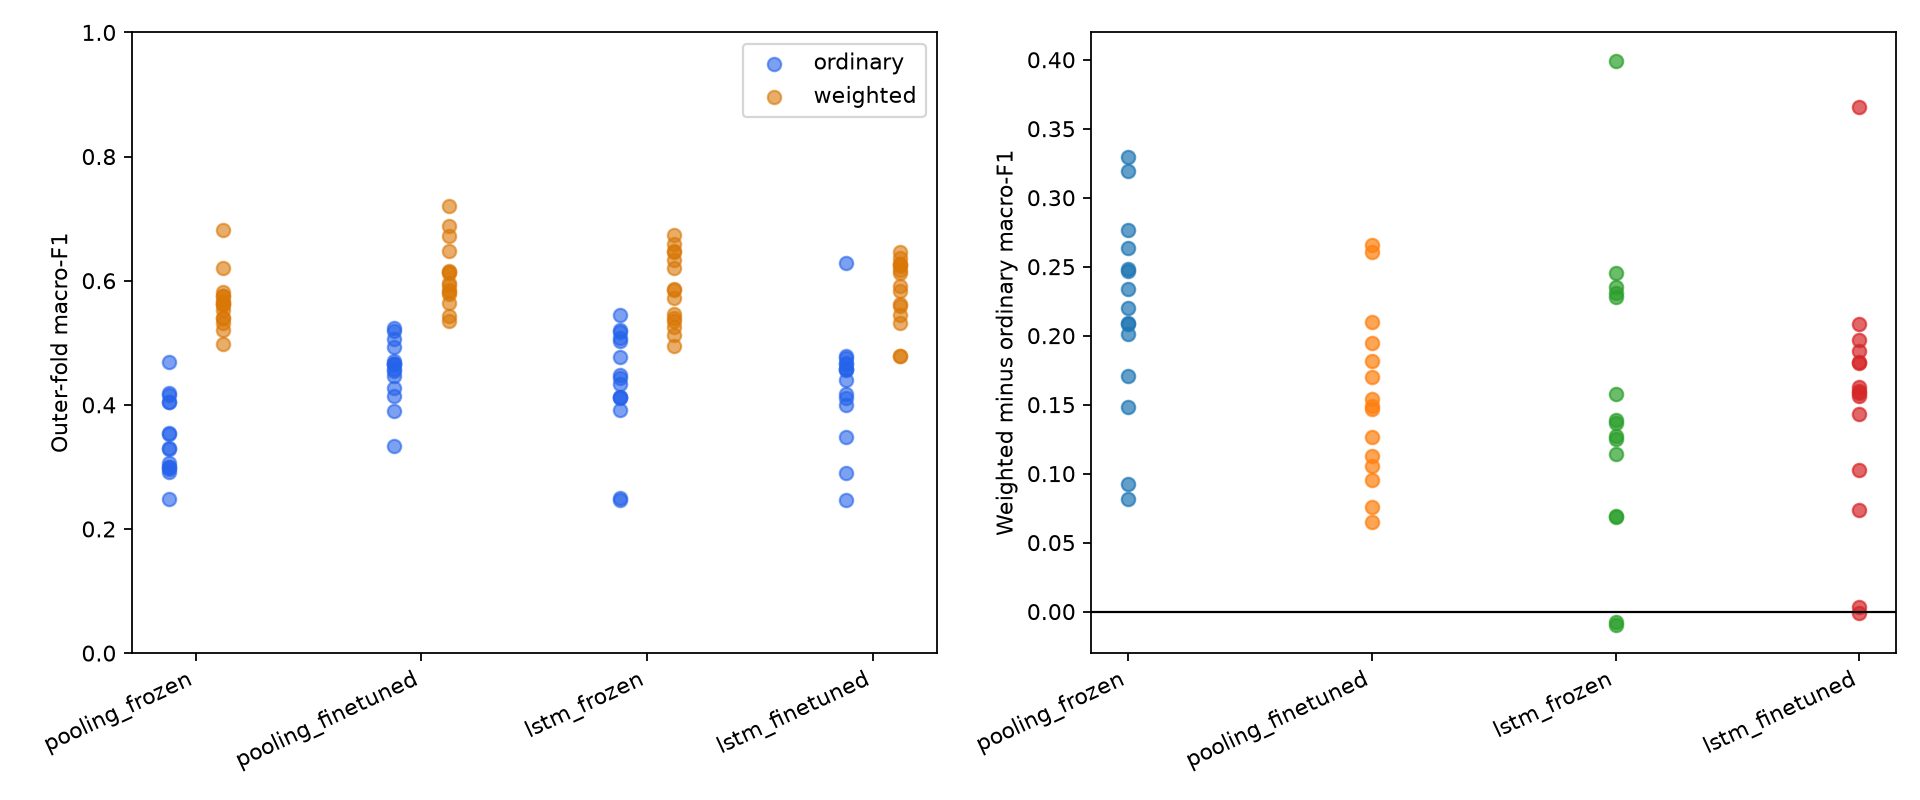

*Fold scores and matched changes from ordinary to weighted loss. Each condition has 3 seeds ? 5 folds.*

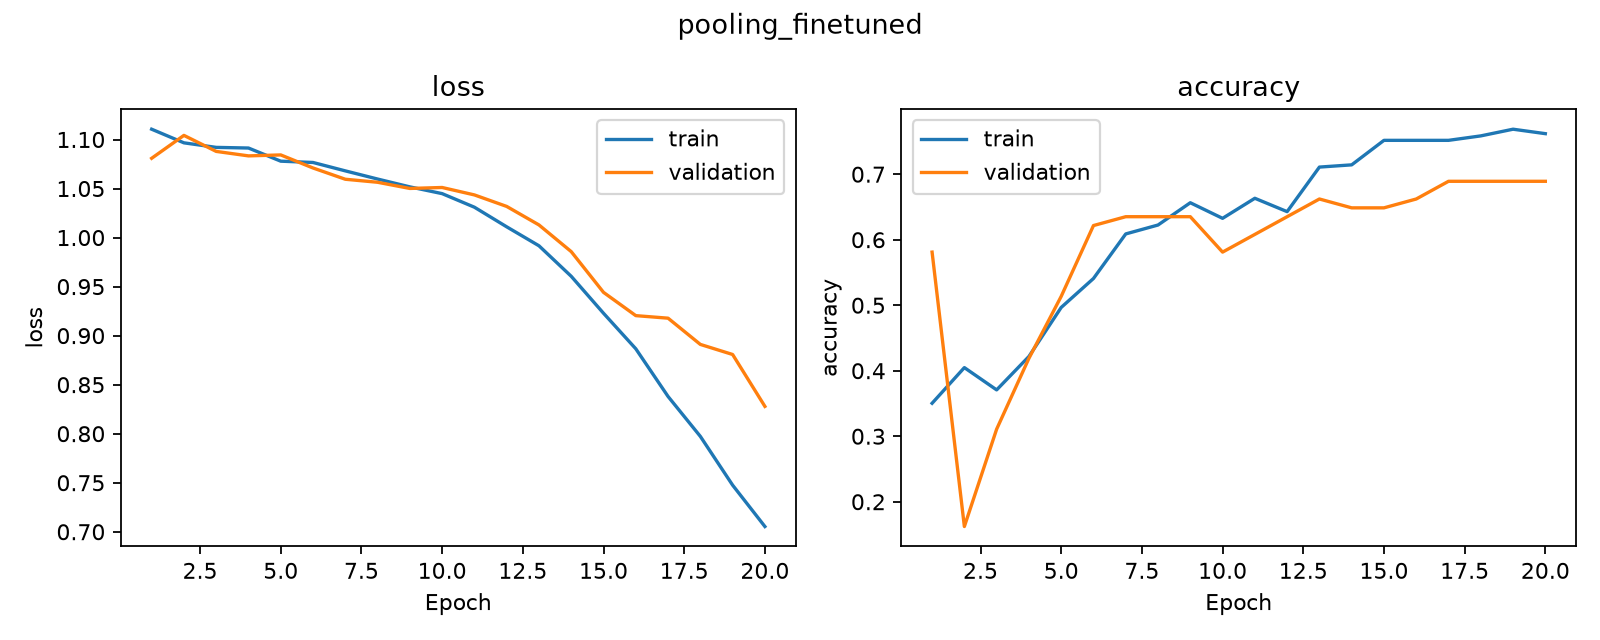

*Illustrative pooling run, seed 0/fold 0; this is not an average learning curve. Training loss is weighted, validation loss is not.*

In [4]:
table(loss_summary[loss_summary.system.str.startswith('pooling')][
    ['condition', 'system', 'macro_f1_mean', 'macro_f1_std', 'accuracy_mean', 'stance_f1_mean']
])
figure(LOSS / 'loss_comparison.png',
       'Fold scores and matched changes from ordinary to weighted loss. Each condition has 3 seeds ? 5 folds.')
figure(WEIGHTED0 / 'pooling_finetuned' / 'seed-0_fold-0' / 'learning_curve.png',
       'Illustrative pooling run, seed 0/fold 0; this is not an average learning curve. Training loss is weighted, validation loss is not.')

Weighting raises fine-tuned pooling's macro-F1 from **0.456 to 0.610**, improving all 15 paired folds. Accuracy stays near **66.4%**: the benefit is better class balance. Weighted training loss and unweighted validation loss are different objectives.

A matched Project 1 baseline table is still missing; we do not yet claim an improvement over that project.

### Adding an LSTM

The one-layer LSTM has 64 hidden units and uses the same tokenizer and classification head as pooling. Packed sequences handle padding. The model components come from the tutorial.

,condition,system,macro_f1_mean,macro_f1_std,accuracy_mean
0,ordinary,lstm_finetuned,0.429,0.089,0.636
1,ordinary,lstm_frozen,0.435,0.089,0.648
2,ordinary,pooling_finetuned,0.456,0.050,0.664
3,ordinary,pooling_frozen,0.348,0.062,0.615
4,weighted,lstm_finetuned,0.581,0.054,0.673
5,weighted,lstm_frozen,0.585,0.059,0.653
6,weighted,pooling_finetuned,0.610,0.052,0.664
7,weighted,pooling_frozen,0.565,0.044,0.621


system,lstm_finetuned,lstm_frozen,pooling_finetuned,pooling_frozen
seed,,,,
0,0.585,0.593,0.654,0.581
3,0.580,0.602,0.596,0.559
5,0.578,0.561,0.580,0.555


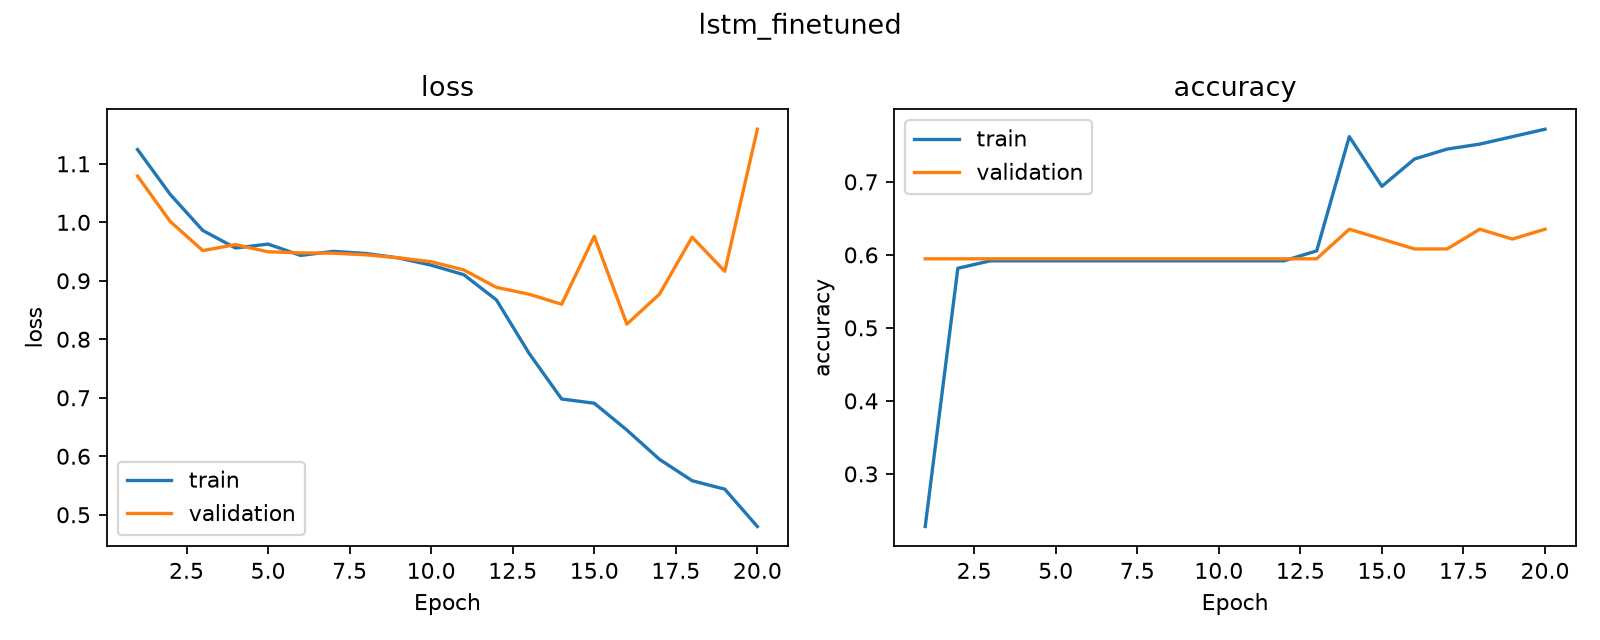

*Illustrative LSTM run, seed 0/fold 0: falling training loss with worsening late validation loss indicates overfitting.*

In [5]:
table(loss_summary[['condition', 'system', 'macro_f1_mean', 'macro_f1_std', 'accuracy_mean']])
weighted_seeds = seed_means[seed_means.condition == 'weighted'].pivot(
    index='seed', columns='system', values='macro_f1'
)
table(weighted_seeds)
figure(ORDINARY0 / 'lstm_finetuned' / 'seed-0_fold-0' / 'learning_curve.png',
       'Illustrative LSTM run, seed 0/fold 0: falling training loss with worsening late validation loss indicates overfitting.')

LSTM does not consistently outperform pooling. Weighted fine-tuned pooling has the best overall mean, but frozen LSTM wins for seed 3. Some LSTM runs overfit, with training loss falling while validation loss rises.

### Understanding the errors

We examine length, adjusted OOV rate, and a lexical negation flag using seed-0 predictions. Group sizes and class distributions matter when interpreting accuracy.

,system,support_ordinary,recall_ordinary,recall_weighted,precision_ordinary,precision_weighted,f1_ordinary,f1_weighted
0,lstm_finetuned,83,0.000,0.386,0.000,0.451,0.000,0.416
1,lstm_frozen,83,0.012,0.349,1.000,0.426,0.024,0.384
2,pooling_finetuned,83,0.012,0.554,0.250,0.469,0.023,0.508
3,pooling_frozen,83,0.000,0.422,0.000,0.380,0.000,0.400


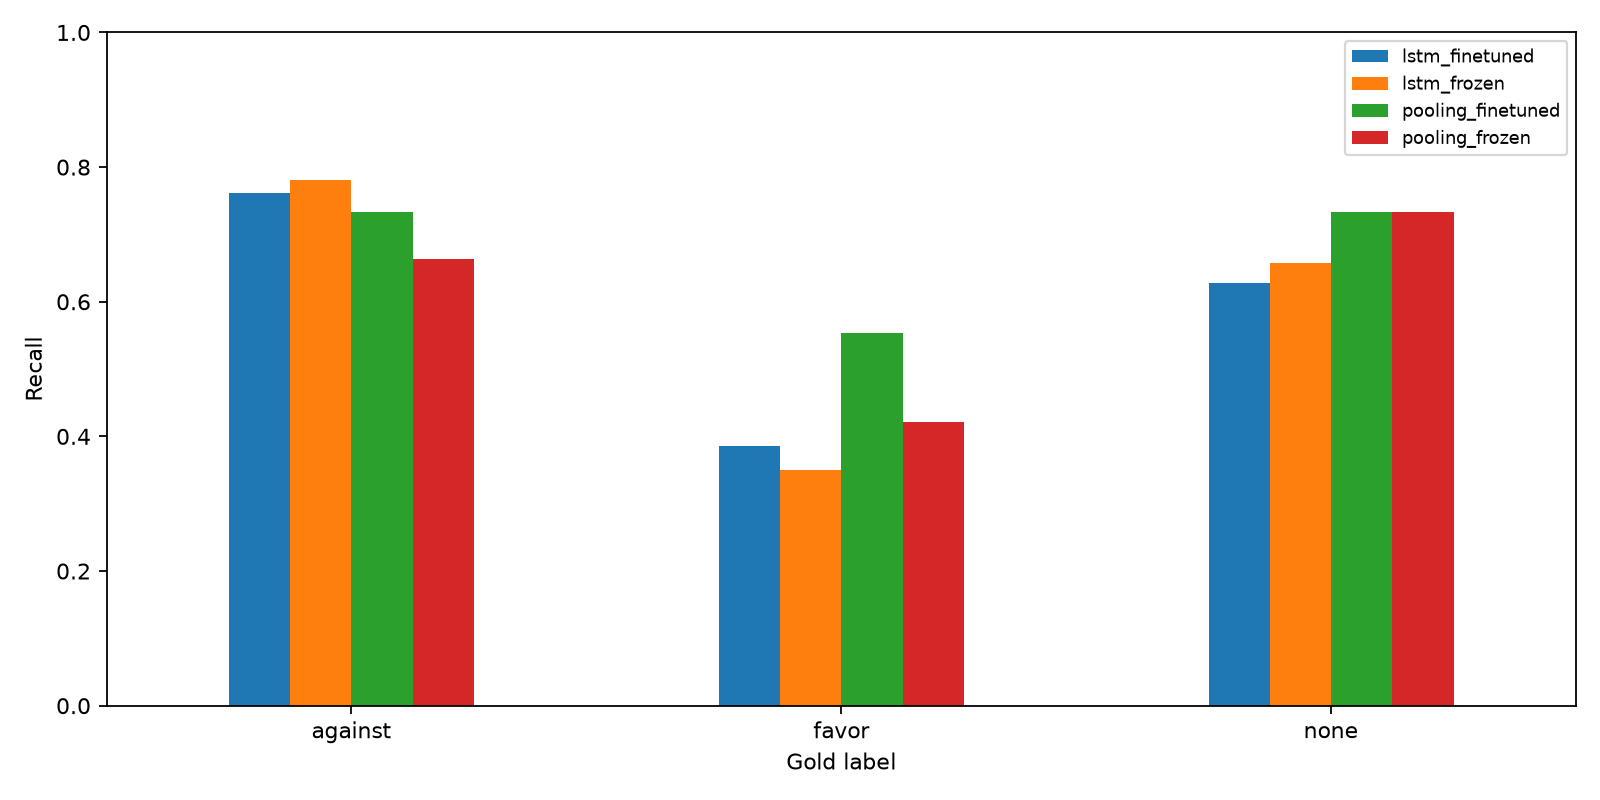

*Weighted models, seed 0: per-class recall over out-of-fold predictions.*

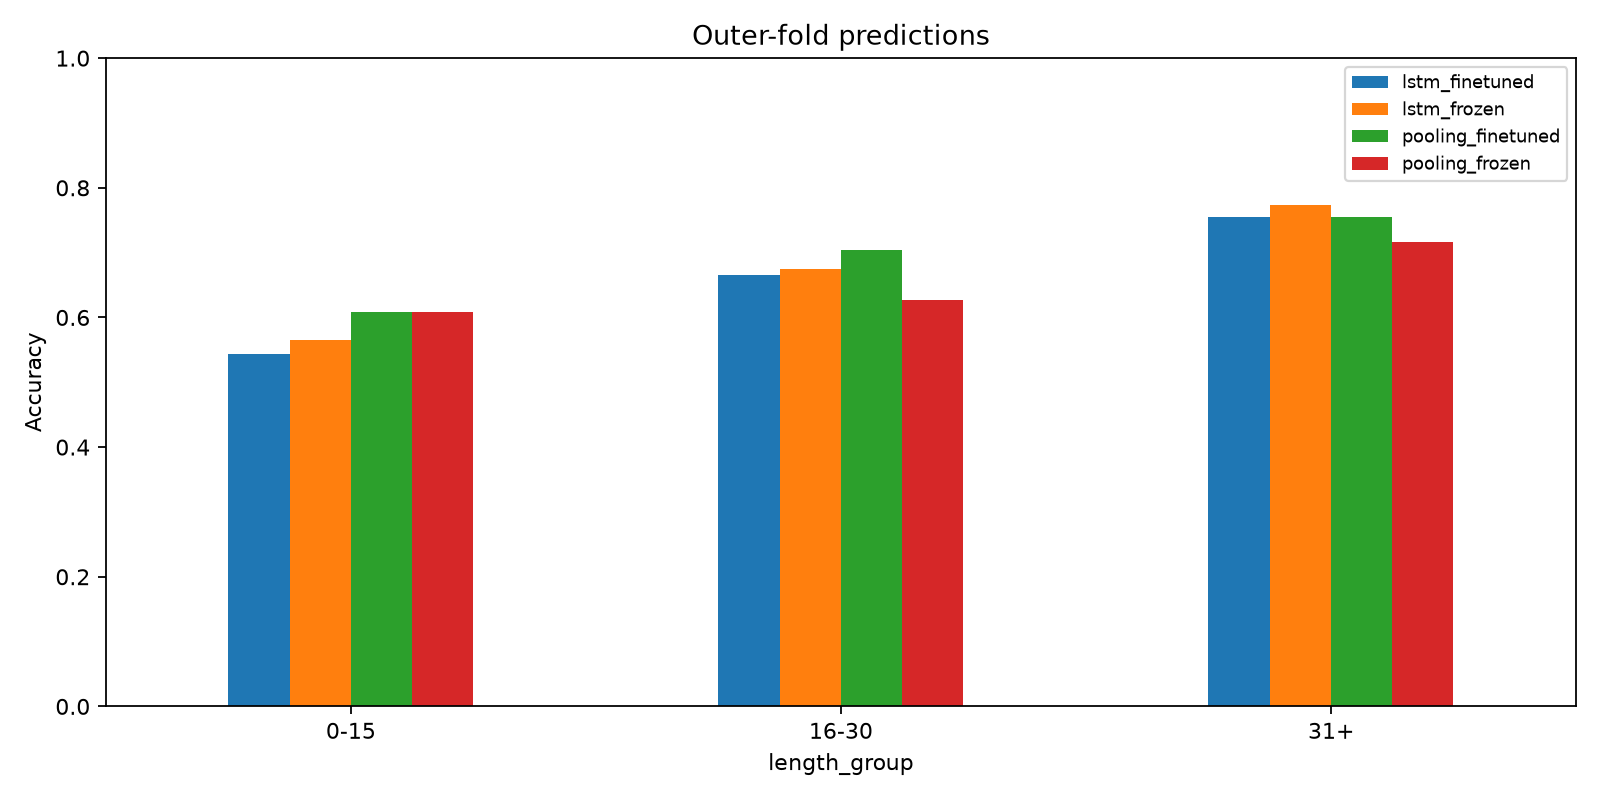

*Length-group accuracy; class composition differs between groups.*

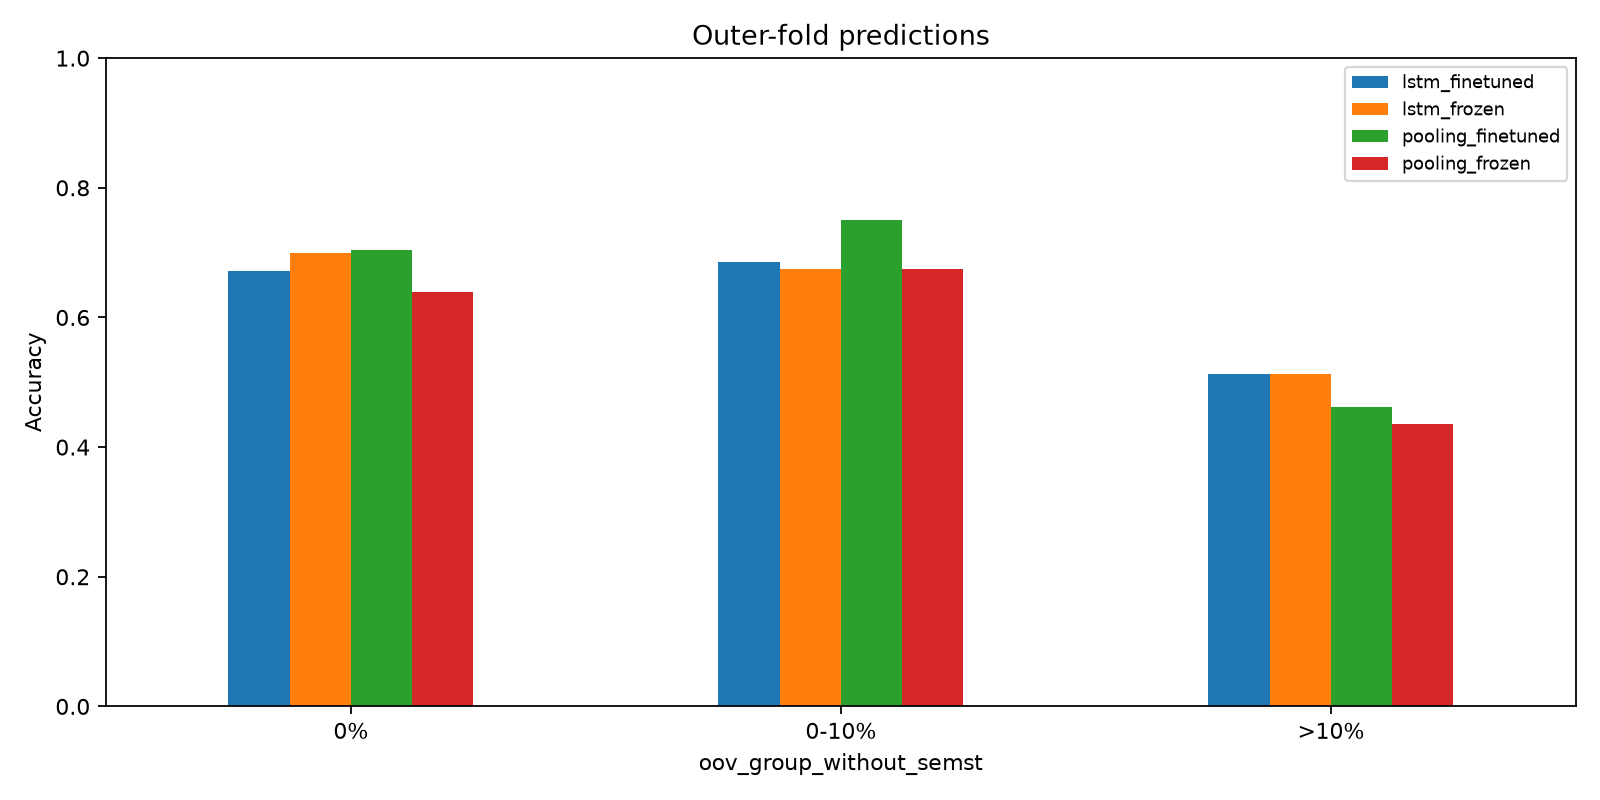

*OOV-group accuracy after excluding the fixed semst token from the analysis only.*

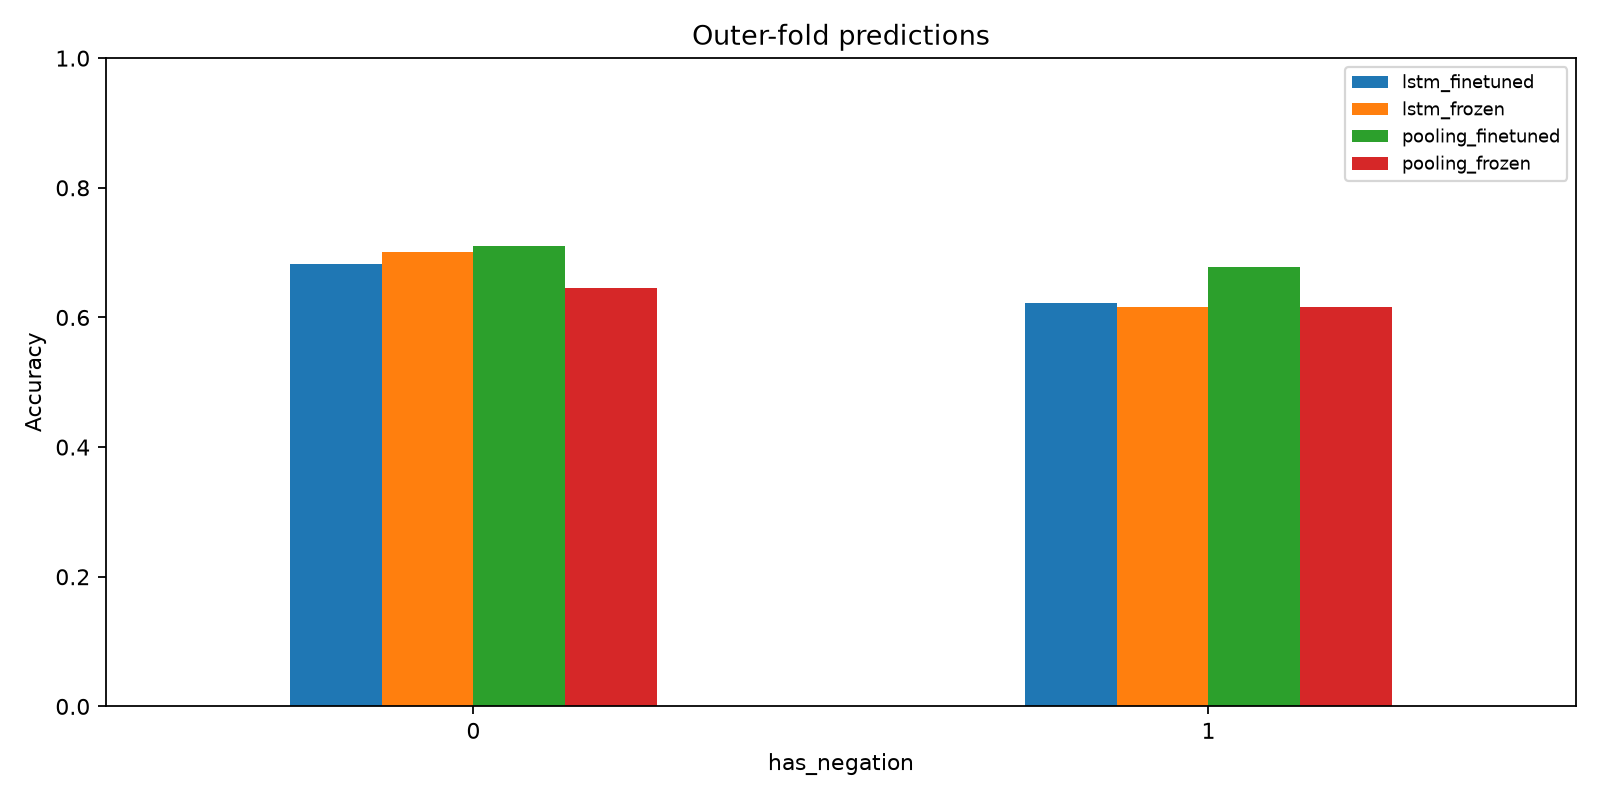

*Lexical negation groups; this flag does not model negation scope.*

In [6]:
ordinary_classes = pd.read_csv(ORDINARY0 / 'analysis' / 'class_metrics.csv')
weighted_classes = pd.read_csv(WEIGHTED0 / 'analysis' / 'class_metrics.csv')
favor = ordinary_classes[ordinary_classes.label == 'favor'].merge(
    weighted_classes[weighted_classes.label == 'favor'], on=['system', 'label'],
    suffixes=('_ordinary', '_weighted'), validate='one_to_one'
)
table(favor[['system', 'support_ordinary', 'recall_ordinary', 'recall_weighted',
             'precision_ordinary', 'precision_weighted', 'f1_ordinary', 'f1_weighted']])
figure(WEIGHTED0 / 'analysis' / 'class_recall.png', 'Weighted models, seed 0: per-class recall over out-of-fold predictions.')
figure(WEIGHTED0 / 'analysis' / 'length_group_accuracy.png', 'Length-group accuracy; class composition differs between groups.')
figure(WEIGHTED0 / 'analysis' / 'oov_group_without_semst_accuracy.png', 'OOV-group accuracy after excluding the fixed semst token from the analysis only.')
figure(WEIGHTED0 / 'analysis' / 'has_negation_accuracy.png', 'Lexical negation groups; this flag does not model negation scope.')

For fine-tuned pooling, weighting raises `favor` recall from **1.2% to 55.4%**, with **46.9% precision**. The number of `favor` examples missed by all four models falls from 82 to 27 out of 83.

Longer tweets contain more majority-class examples, so higher accuracy does not establish a length advantage. Many errors have zero adjusted OOV. On 28 `favor` tweets with negation, recall rises from 0% to 67.9%; this does not prove an understanding of negation.

,sample_id,text,oov_rate_without_semst,has_negation,pooling_finetuned,lstm_finetuned,n_systems_correct
0,train:108,Yes Islam is the mother load of bad ideas! Christianity is not far behind! #athiest #SemST,0.000000,1,favor,favor,4
1,train:12,"If you regularly base your thoughts on superstitions, you might not be able to think well. #freethinker #SemST",0.000000,1,favor,favor,4
12,train:67,"@user if u discriminate based on ur religion, be ready to be discriminated against for having that religion. @user #SemST",0.000000,0,favor,favor,4
56,train:102,Could all those who believe in a god please leave. The meeting will now continue for the grown ups only. #SemST,0.000000,0,against,none,0
57,train:105,Evidence-based thought just works out better than superstition-based thought. #freethinker #SemST,0.153846,0,none,none,0


,system,label,feature,group,n,recall
84,pooling_finetuned,none,has_negation,0,77,0.766
85,pooling_finetuned,none,has_negation,1,28,0.643
86,pooling_finetuned,against,has_negation,0,186,0.753
87,pooling_finetuned,against,has_negation,1,87,0.690
88,pooling_finetuned,favor,has_negation,0,55,0.491
89,pooling_finetuned,favor,has_negation,1,28,0.679


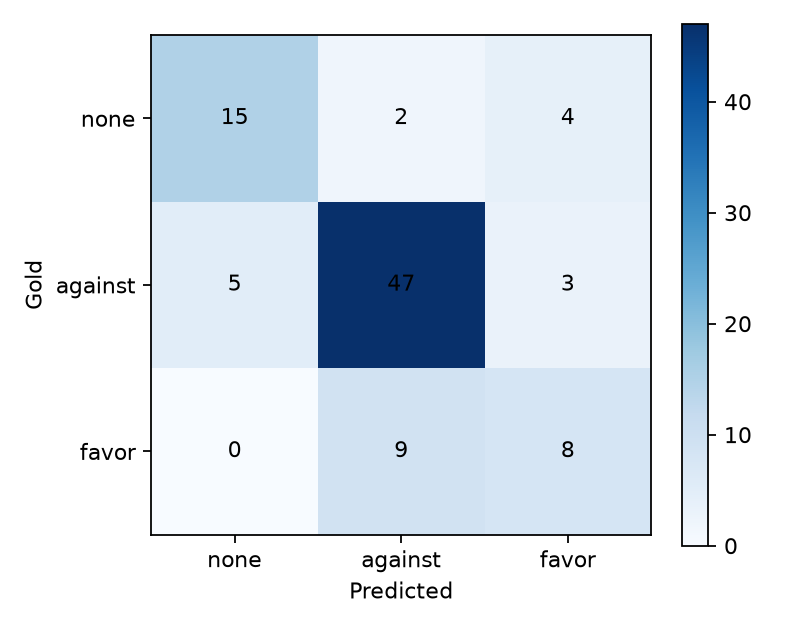

*Illustrative confusion matrix, weighted fine-tuned pooling, seed 0/fold 0.*

In [7]:
cases = pd.read_csv(WEIGHTED0 / 'analysis' / 'favor_cases.csv', keep_default_na=False)
# Fixed IDs illustrate successes and failures; they are not a random sample.
selected_ids = ['train:67', 'train:102', 'train:105', 'train:108', 'train:12']
examples = cases[cases.sample_id.isin(selected_ids)][
    ['sample_id', 'text', 'oov_rate_without_semst', 'has_negation',
     'pooling_finetuned', 'lstm_finetuned', 'n_systems_correct']
]
with pd.option_context('display.max_colwidth', None):
    display(examples)
class_features = pd.read_csv(WEIGHTED0 / 'analysis' / 'class_feature_metrics.csv')
table(class_features[(class_features.system == 'pooling_finetuned') &
                     (class_features.feature == 'has_negation')])
figure(WEIGHTED0 / 'pooling_finetuned' / 'seed-0_fold-0' / 'confusion_matrix.png',
       'Illustrative confusion matrix, weighted fine-tuned pooling, seed 0/fold 0.')

Stance depends on the target: criticism of religion may support atheism. The examples suggest difficulties beyond word coverage, but do not reveal which features the networks used. These analyses are descriptive, not causal.

### The contribution of pretraining

We first inspect task-related neighbours, then compare GloVe with trainable random vectors. Vocabulary, dimensions, classifier initialization, weighted loss, splits, and training budget remain matched.

In [8]:
neighbours = pd.read_csv(RESULTS / 'embedding_neighbours.csv')
examples = neighbours[neighbours['rank'].between(1, 5)].copy()
compact = examples.groupby('query', sort=False).apply(
    lambda g: ', '.join(g['neighbour'].astype(str)), include_groups=False
).rename('five_nearest_words').reset_index()
display(compact)

,query,five_nearest_words
0,atheism,"agnosticism, atheistic, ideology, materialism,..."
1,atheist,"agnostic, atheistic, persecuted, jew, atheism"
2,religion,"beliefs, religious, christianity, religions, b..."
3,religious,"religion, secular, muslim, islamic, beliefs"
4,god,"divine, heaven, holy, gods, faith"
5,evidence,"case, findings, suggesting, unclear, claims"
6,superstition,"superstitions, materialism, individualism, hed..."
7,believe,"say, reason, indeed, might, why"
8,disbelief,"disgust, astonishment, amazement, exasperation..."
9,not,"be, if, because, should, could"


GloVe captures associations such as `atheism` with `agnosticism`. It also mixes senses: `disbelief` is close to `astonishment` and `disgust`. These qualitative examples motivate a controlled classification comparison.

,initialization,system,macro_f1_mean,macro_f1_std,accuracy_mean,stance_f1_mean
0,pretrained,lstm_finetuned,0.581,0.054,0.673,0.578
1,pretrained,pooling_finetuned,0.610,0.052,0.664,0.601
2,random,lstm_finetuned,0.386,0.076,0.502,0.463
3,random,pooling_finetuned,0.483,0.033,0.556,0.528


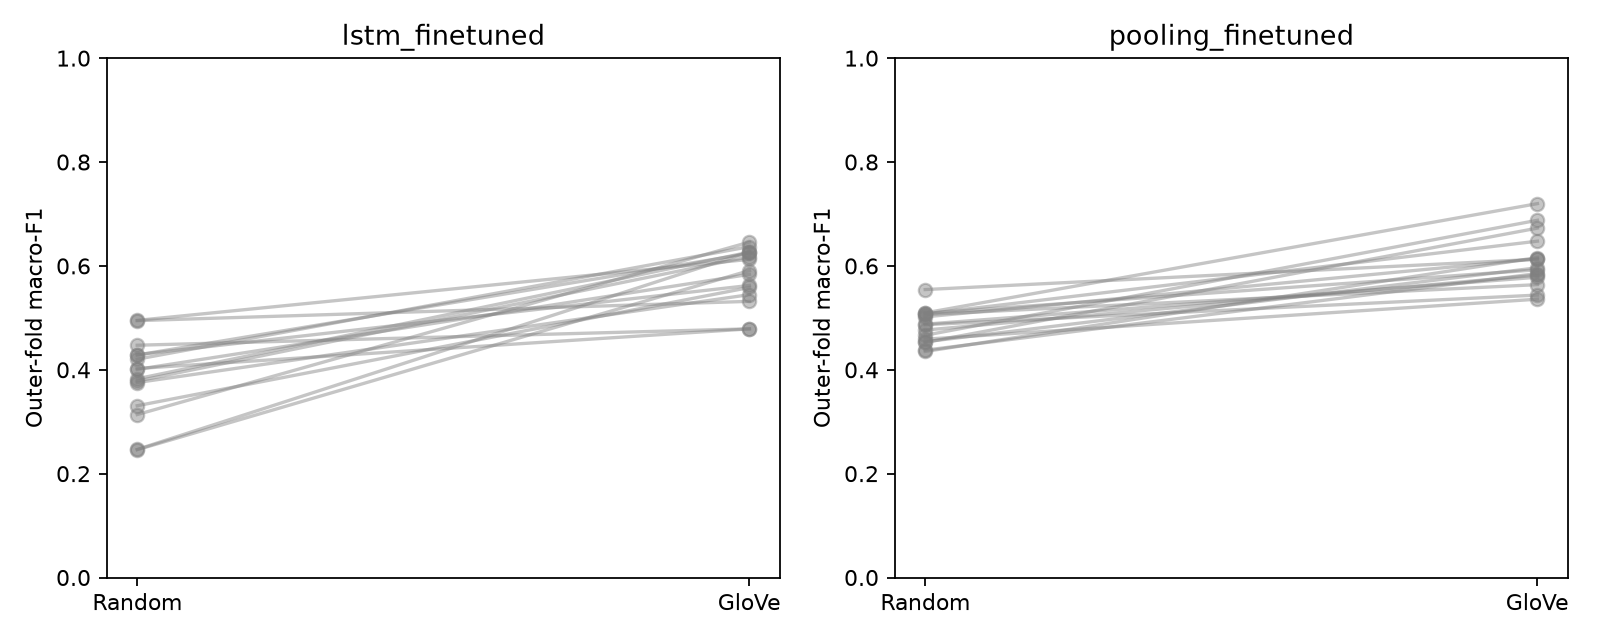

*Each line connects the same seed/fold under random initialization and GloVe. All embeddings are trainable.*

,system,mean_difference,improved_folds,paired_folds
0,lstm_finetuned,0.195,15,15
1,pooling_finetuned,0.127,15,15


In [9]:
table(embedding_summary[['initialization', 'system', 'macro_f1_mean', 'macro_f1_std',
                         'accuracy_mean', 'stance_f1_mean']])
figure(EMBED / 'initialization_comparison.png',
       'Each line connects the same seed/fold under random initialization and GloVe. All embeddings are trainable.')
initialization_pairs = pd.read_csv(EMBED / 'paired_initialization_differences.csv')
table(initialization_pairs.groupby('system')['macro_f1_difference'].agg(
    mean_difference='mean', improved_folds=lambda x: int((x > 0).sum()), paired_folds='count'
).reset_index())

GloVe improves macro-F1 from **0.483 to 0.610** for pooling and **0.386 to 0.581** for LSTM, winning all 15 paired folds for both. Pretraining helps under this budget; different optimization settings could change the random-vector results.

### Reducing the training data

The 50% condition subsamples only the inner training set. Validation and evaluation remain unchanged, and class weights are recomputed. Both conditions use 20 epochs, so fewer examples also mean fewer optimizer steps.

With half the fitting data, mean macro-F1 falls from **0.610 to 0.505** for pooling and from **0.581 to 0.482** for LSTM. Both models benefit from more training data under this budget; this does not isolate data diversity from the number of optimizer updates.

,system,macro_f1_half,macro_f1_full,macro_f1_full_minus_half
0,lstm_finetuned,0.482,0.581,0.100
1,pooling_finetuned,0.505,0.610,0.105


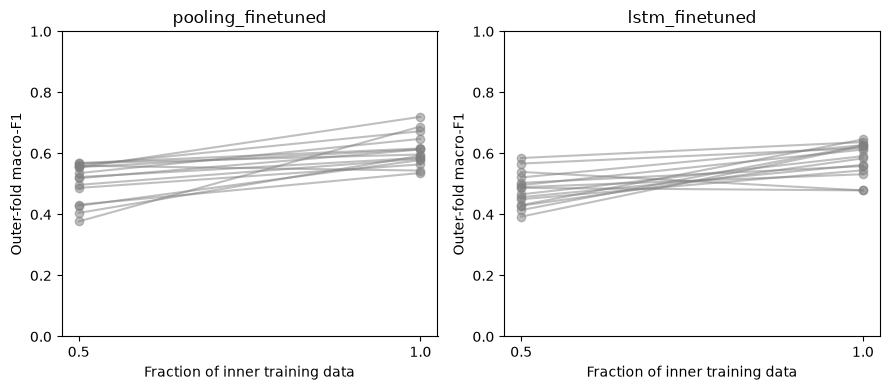

In [10]:
size_dirs = sorted(RESULTS.glob('weighted_pretrained_fraction0.5_*'))
if not size_dirs:
    display(Markdown('**Pending:** the 50% training-data experiment has not produced results yet.'))
else:
    half_run = size_dirs[-1]
    metrics_path = half_run / 'fold_metrics.csv'
    half = pd.read_csv(metrics_path) if metrics_path.exists() else pd.DataFrame()
    if not (half_run / 'summary.csv').exists() or len(half) != 30:
        display(Markdown(f'**In progress:** {len(half)}/30 reduced-data fold runs completed when this notebook was executed. '
                         'Partial scores are not compared. Re-run this notebook after training finishes.'))
    else:
        full = pd.concat([pd.read_csv(p / 'fold_metrics.csv') for p in [WEIGHTED0, WEIGHTED35]])
        full = full[full.system.isin(['pooling_finetuned', 'lstm_finetuned'])]
        paired = full.merge(half, on=['system', 'seed', 'fold'], suffixes=('_full', '_half'),
                            validate='one_to_one')
        if len(paired) != 30:
            raise ValueError('Missing matched full/half-data results')
        for row in paired.itertuples():
            name = f'seed-{row.seed}_fold-{row.fold}'
            full_root = WEIGHTED0 if row.seed == 0 else WEIGHTED35
            full_ids = pd.read_csv(full_root / row.system / name / 'split_ids.csv')
            half_ids = pd.read_csv(half_run / row.system / name / 'split_ids.csv')
            for subset in ['dev', 'outer_eval']:
                if full_ids[full_ids.subset == subset].sample_id.tolist() != half_ids[half_ids.subset == subset].sample_id.tolist():
                    raise ValueError('Evaluation partitions differ')
            if not set(half_ids[half_ids.subset == 'fit'].sample_id).issubset(
                    set(full_ids[full_ids.subset == 'fit'].sample_id)):
                raise ValueError('The reduced training set is not a subset')
        paired['macro_f1_full_minus_half'] = paired.macro_f1_full - paired.macro_f1_half
        table(paired.groupby('system')[['macro_f1_half', 'macro_f1_full',
                                       'macro_f1_full_minus_half']].mean().reset_index())
        paired.to_csv(RESULTS / 'data_size_paired_comparison.csv', index=False)
        fig, axes = plt.subplots(1, 2, figsize=(9, 4))
        for ax, system in zip(axes, ['pooling_finetuned', 'lstm_finetuned']):
            for row in paired[paired.system == system].itertuples():
                ax.plot([0.5, 1.0], [row.macro_f1_half, row.macro_f1_full], color='gray', alpha=0.5, marker='o')
            ax.set(xticks=[0.5, 1.0], xlabel='Fraction of inner training data',
                   ylabel='Outer-fold macro-F1', title=system, ylim=(0, 1))
        plt.tight_layout()
        plt.show()

## Conclusion

**Class weighting and pretraining provide the clearest gains; LSTM offers no consistent advantage over pooling.** Weighted fine-tuned pooling reaches the best mean macro-F1 of **0.610**. Reducing the fitting data by half lowers both models' macro-F1 by about 0.10.

The dataset is small, settings are fixed, and subgroup analysis covers seed 0. A matched Project 1 comparison and a multi-seed review of remaining `favor` errors are still needed before fixing a final model and evaluating the reserved test split.